<a href="https://colab.research.google.com/github/Kazato-ce/Computer-Vision/blob/main/B%C3%A0iT%E1%BA%ADp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thông tin sinh viên

*   MSSV: 24521338
*   Họ và tên: Nguyễn Đoàn Thanh Phong


# I.Chuẩn bị
## 1.Kết nối Google Drive

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Khai báo thư viện và đường dẫn

In [15]:
import os, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Giải nén dataset vào /content nếu chưa giải nén
if not os.path.exists("/content/HoaVietNam2027"):
    print("Đang giải nén file dataset...")
    !unzip -q /content/HoaVietNam2027.zip -d /content/

DATA_DIR     = "/content/HoaVietNam2027"
train_folder = os.path.join(DATA_DIR, "train")
test_folder  = os.path.join(DATA_DIR, "test")

Đang giải nén file dataset...


## 3. Đọc dữ liệu
Hàm đọc ảnh, đồng thời lưu **đường dẫn file** để Yêu cầu 3 có thể in danh sách tên ảnh.

In [14]:
!unzip -l /content/HoaVietNam2027.zip

Archive:  /content/HoaVietNam2027.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2026-10-14 01:47   HoaVietNam2027/
        0  2026-10-14 05:11   HoaVietNam2027/test/
        0  2026-10-14 01:47   HoaVietNam2027/test/Cuc/
   378881  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0041.jpg
    40460  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0042.jpg
  2009105  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0043.jpg
   309466  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0044.jpg
    49550  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0045.jpg
    33472  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0046.jpg
    97615  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0047.jpg
    51683  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0048.jpg
   147422  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0049.jpg
    23017  2026-10-14 01:47   HoaVietNam2027/test/Cuc/0050.jpg
        0  2026-10-14 01:47   HoaVietNam2027/test/Dao/
   134004  2026-10-14 01:47   HoaVietNam2027/test/Dao/0

In [16]:
def load_dataset(folder):
    images, labels, paths = [], [], []
    class_names = sorted(d for d in os.listdir(folder)
                         if os.path.isdir(os.path.join(folder, d)))
    for label, cname in enumerate(class_names):
        for p in sorted(glob.glob(os.path.join(folder, cname, "*.*"))):
            img = cv2.imread(p)           # ảnh BGR
            if img is None:               # bỏ qua file không phải ảnh
                continue
            images.append(img)
            labels.append(label)
            paths.append(p)
    return images, np.array(labels), paths, class_names

train_images, y_train, train_paths, class_names = load_dataset(train_folder)
test_images,  y_test,  test_paths,  class_names_test = load_dataset(test_folder)
assert class_names == class_names_test, "Thư mục train và test không cùng danh sách loài hoa!"

print("Các lớp:", class_names)
print("Số ảnh train:", len(train_images), "| Số ảnh test:", len(test_images))
print("Số ảnh mỗi lớp (train):", dict(zip(class_names, np.bincount(y_train))))
print("Số ảnh mỗi lớp (test) :", dict(zip(class_names, np.bincount(y_test))))

Các lớp: ['Cuc', 'Dao', 'Ga', 'Hong', 'Lan', 'Mai', 'Sen', 'Tho']
Số ảnh train: 285 | Số ảnh test: 92
Số ảnh mỗi lớp (train): {'Cuc': np.int64(40), 'Dao': np.int64(35), 'Ga': np.int64(40), 'Hong': np.int64(35), 'Lan': np.int64(35), 'Mai': np.int64(30), 'Sen': np.int64(40), 'Tho': np.int64(30)}
Số ảnh mỗi lớp (test) : {'Cuc': np.int64(10), 'Dao': np.int64(12), 'Ga': np.int64(15), 'Hong': np.int64(15), 'Lan': np.int64(10), 'Mai': np.int64(10), 'Sen': np.int64(10), 'Tho': np.int64(10)}


Kiểm Tra

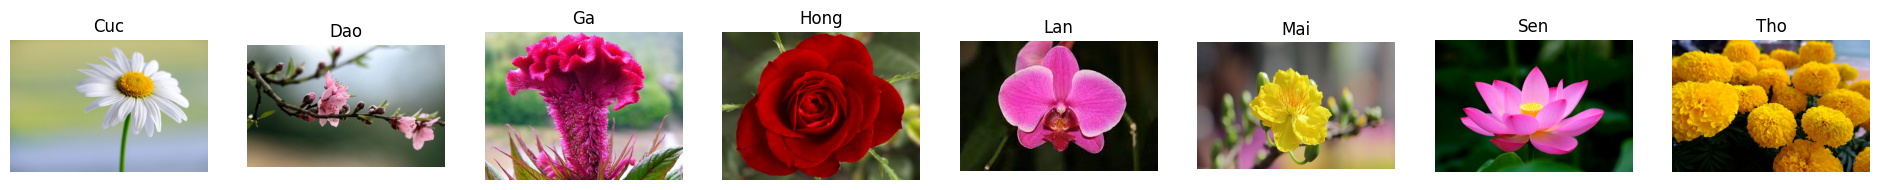

In [17]:
plt.figure(figsize=(3 * len(class_names), 3))
for c, name in enumerate(class_names):
    idx = np.where(y_train == c)[0][0]
    plt.subplot(1, len(class_names), c + 1)
    plt.imshow(cv2.cvtColor(train_images[idx], cv2.COLOR_BGR2RGB))
    plt.title(name); plt.axis("off")
plt.show()

# II.Các yêu cầu của bài

# Yêu cầu 1: KNeighborsClassifier + Histogram RGB
Tìm bộ tham số cho độ chính xác cao nhất:
* `n_neighbors`: 1 – 10
* `weights`: `uniform`, `distance`
* `metric`: `braycurtis`, `canberra`, `correlation`, `cosine`, `euclidean`, `minkowski`

Đặc trưng: histogram **riêng từng kênh R, G, B**, mỗi kênh **256 bin**, rồi nối lại thành vector 768 chiều.
Histogram được chia cho tổng số điểm ảnh (chuẩn hóa tổng = 1) để ảnh có kích thước khác nhau vẫn so sánh được.

In [18]:
def hist_rgb(img_bgr, bins=256):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    feats = []
    for ch in range(3):                                   # R, G, B tính riêng
        h = cv2.calcHist([rgb], [ch], None, [bins], [0, 256]).flatten()
        feats.append(h / h.sum())                         # chuẩn hóa
    return np.concatenate(feats)                          # 3 x 256 = 768 chiều

X_train_rgb = np.array([hist_rgb(im) for im in train_images])
X_test_rgb  = np.array([hist_rgb(im) for im in test_images])
print("Kích thước:", X_train_rgb.shape, X_test_rgb.shape)

Kích thước: (285, 768) (92, 768)


In [19]:
n_neighbors_options = range(1, 11)
weight_options      = ['uniform', 'distance']
metric_options      = ['braycurtis', 'canberra', 'correlation', 'cosine', 'euclidean', 'minkowski']

rows = []
for k, w, m in product(n_neighbors_options, weight_options, metric_options):
    knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric=m)
    knn.fit(X_train_rgb, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test_rgb))
    rows.append({"n_neighbors": k, "weights": w, "metric": m, "accuracy": acc})

results = pd.DataFrame(rows)
# Nhiều bộ tham số có thể bằng điểm nhau -> ưu tiên accuracy cao nhất, rồi n_neighbors nhỏ nhất
results = results.sort_values(["accuracy", "n_neighbors"], ascending=[False, True]).reset_index(drop=True)

print("Top 10 bộ tham số tốt nhất:")
display(results.head(10))

best = results.iloc[0]
best_params = {"n_neighbors": int(best.n_neighbors), "weights": best.weights, "metric": best.metric}
print("\nTHAM SỐ TỐI ƯU:", best_params)
print(f"Độ chính xác cao nhất: {best.accuracy:.4f}")

Top 10 bộ tham số tốt nhất:


,n_neighbors,weights,metric,accuracy
0,3,distance,braycurtis,0.565217
1,4,distance,braycurtis,0.565217
2,8,distance,canberra,0.565217
3,3,uniform,braycurtis,0.554348
4,10,distance,canberra,0.554348
5,10,distance,cosine,0.554348
6,5,uniform,braycurtis,0.543478
7,5,distance,braycurtis,0.543478
8,7,distance,braycurtis,0.543478
9,9,uniform,braycurtis,0.543478



THAM SỐ TỐI ƯU: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'braycurtis'}
Độ chính xác cao nhất: 0.5652


Độ chính xác trung bình theo từng metric (giúp nhận xét metric nào hợp với histogram)

In [20]:
print(results.groupby("metric")["accuracy"].agg(["max", "mean"]).sort_values("max", ascending=False).round(4))

                max    mean
metric                     
braycurtis   0.5652  0.5310
canberra     0.5652  0.5109
cosine       0.5543  0.4674
correlation  0.5217  0.4804
euclidean    0.5109  0.4560
minkowski    0.5109  0.4560


Chi tiết mô hình tốt nhất: báo cáo phân loại + ma trận nhầm lẫn

              precision    recall  f1-score   support

         Cuc       0.56      0.90      0.69        10
         Dao       0.53      0.75      0.62        12
          Ga       0.65      0.73      0.69        15
        Hong       0.27      0.20      0.23        15
         Lan       0.50      0.40      0.44        10
         Mai       1.00      0.60      0.75        10
         Sen       0.60      0.30      0.40        10
         Tho       0.58      0.70      0.64        10

    accuracy                           0.57        92
   macro avg       0.59      0.57      0.56        92
weighted avg       0.57      0.57      0.55        92



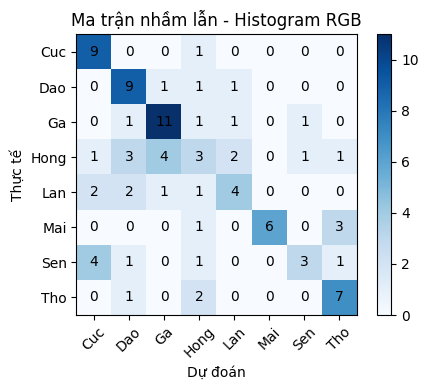

In [21]:
best_knn = KNeighborsClassifier(**best_params).fit(X_train_rgb, y_train)
y_pred_rgb = best_knn.predict(X_test_rgb)
print(classification_report(y_test, y_pred_rgb, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred_rgb)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Ma trận nhầm lẫn - Histogram RGB")
plt.tight_layout(); plt.show()

# Yêu cầu 2: So sánh các đặc trưng màu sắc (dùng tham số tối ưu ở Yêu cầu 1)
1. Histogram HSV 8×8×8
2. Moment màu
3. Màu chủ đạo

## 1. Các hàm rút trích đặc trưng

In [22]:
def hist_hsv(img_bgr, bins=8):
    # Histogram 3D trên H, S, V. Lưu ý OpenCV: H thuộc [0,180), S và V thuộc [0,256)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], None, [bins, bins, bins],
                     [0, 180, 0, 256, 0, 256]).flatten()
    return h / h.sum()                                    # bins^3 chiều

def color_moments(img_bgr):
    # 3 moment (mean, std, skewness) x 3 kênh = 9 chiều
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(np.float64)
    mean = rgb.mean(axis=0)
    std  = rgb.std(axis=0)
    skew = np.cbrt(np.mean((rgb - mean) ** 3, axis=0))    # căn bậc 3 của moment bậc 3
    return np.concatenate([mean, std, skew])

def dominant_colors(img_bgr, k=3):
    # Thu nhỏ ảnh để KMeans chạy nhanh; random_state để kết quả lặp lại được
    small = cv2.resize(img_bgr, (64, 64), interpolation=cv2.INTER_AREA)
    px = cv2.cvtColor(small, cv2.COLOR_BGR2RGB).reshape(-1, 3).astype(np.float64)
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(px)
    # QUAN TRỌNG: sắp các cụm theo số điểm ảnh giảm dần, để "màu chủ đạo #1, #2, #3"
    # luôn nằm đúng vị trí giữa các ảnh. Nếu không, KNN so sánh sai cặp màu.
    order = np.argsort(-np.bincount(km.labels_, minlength=k))
    return km.cluster_centers_[order].flatten()           # k x 3 chiều

## 2.Chạy Thực Nghiêm

In [23]:
def evaluate(extract_fn, name):
    Xtr = np.array([extract_fn(im) for im in train_images])
    Xte = np.array([extract_fn(im) for im in test_images])
    model = KNeighborsClassifier(**best_params).fit(Xtr, y_train)
    pred = model.predict(Xte)
    acc = accuracy_score(y_test, pred)
    print(f"{name:<28s} | số chiều = {Xtr.shape[1]:<5d} | accuracy = {acc:.4f}")
    return acc, pred, Xtr, Xte

print("Tham số dùng chung:", best_params, "\n")
acc_rgb = accuracy_score(y_test, y_pred_rgb)
print(f"{'Histogram RGB 256 (YC1)':<28s} | số chiều = {X_train_rgb.shape[1]:<5d} | accuracy = {acc_rgb:.4f}")

acc_hsv8,  pred_hsv8,  _, _ = evaluate(lambda im: hist_hsv(im, 8), "Histogram HSV 8x8x8")
acc_mom,   pred_mom,   _, _ = evaluate(color_moments,              "Moment màu")
acc_dom,   pred_dom,   _, _ = evaluate(dominant_colors,            "Màu chủ đạo (k=3)")

Tham số dùng chung: {'n_neighbors': 3, 'weights': 'distance', 'metric': 'braycurtis'} 

Histogram RGB 256 (YC1)      | số chiều = 768   | accuracy = 0.5652
Histogram HSV 8x8x8          | số chiều = 512   | accuracy = 0.6739
Moment màu                   | số chiều = 9     | accuracy = 0.4457
Màu chủ đạo (k=3)            | số chiều = 9     | accuracy = 0.4457


Bảng biểu đặt chưng

,Đặc trưng,Accuracy
1,Histogram HSV 8x8x8,0.6739
0,Histogram RGB 256 (YC1),0.5652
2,Moment màu,0.4457
3,Màu chủ đạo,0.4457


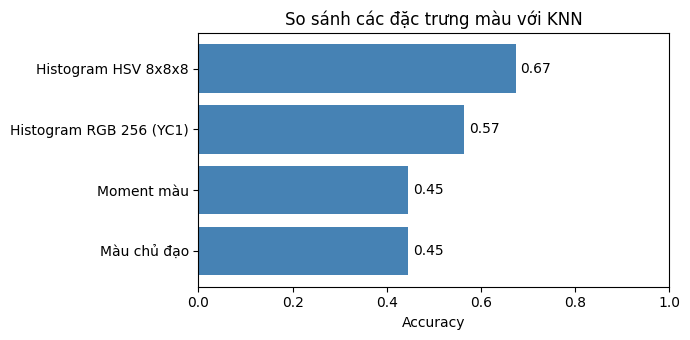

In [24]:
summary = pd.DataFrame({
    "Đặc trưng": ["Histogram RGB 256 (YC1)", "Histogram HSV 8x8x8", "Moment màu", "Màu chủ đạo"],
    "Accuracy":  [acc_rgb, acc_hsv8, acc_mom, acc_dom],
}).sort_values("Accuracy", ascending=False)
display(summary.round(4))

plt.figure(figsize=(7, 3.5))
plt.barh(summary["Đặc trưng"], summary["Accuracy"], color="steelblue")
plt.gca().invert_yaxis(); plt.xlim(0, 1)
for i, v in enumerate(summary["Accuracy"]):
    plt.text(v + 0.01, i, f"{v:.2f}", va="center")
plt.xlabel("Accuracy"); plt.title("So sánh các đặc trưng màu với KNN")
plt.tight_layout(); plt.show()

# Yêu cầu 3: Phân tích lỗi giữa hai đặc trưng
* **A**: Histogram RGB (256 bin/kênh) — chính là kết quả Yêu cầu 1
* **B**: Histogram HSV 16×16×16

In danh sách ảnh test thuộc 3 trường hợp:
1. A sai nhưng B đúng → ưu điểm của B
2. A đúng nhưng B sai → ưu điểm của A
3. A sai và B sai → mẫu khó

## Dự đoán B

In [25]:
X_train_hsv16 = np.array([hist_hsv(im, 16) for im in train_images])
X_test_hsv16  = np.array([hist_hsv(im, 16) for im in test_images])
y_pred_hsv16  = KNeighborsClassifier(**best_params).fit(X_train_hsv16, y_train).predict(X_test_hsv16)

print(f"A (RGB)        : {accuracy_score(y_test, y_pred_rgb):.4f}")
print(f"B (HSV 16x16x16): {accuracy_score(y_test, y_pred_hsv16):.4f}")

A_ok, B_ok = (y_pred_rgb == y_test), (y_pred_hsv16 == y_test)
case1 = np.where(~A_ok &  B_ok)[0]   # A sai, B đúng
case2 = np.where( A_ok & ~B_ok)[0]   # A đúng, B sai
case3 = np.where(~A_ok & ~B_ok)[0]   # cả hai sai
print(f"\nA sai - B đúng: {len(case1)} ảnh | A đúng - B sai: {len(case2)} ảnh | cùng sai: {len(case3)} ảnh")

A (RGB)        : 0.5652
B (HSV 16x16x16): 0.6957

A sai - B đúng: 19 ảnh | A đúng - B sai: 7 ảnh | cùng sai: 21 ảnh


Mô phỏng

In [27]:
def print_list(indices, title):
    print("=" * 90)
    print(f"{title}  ({len(indices)} ảnh)")
    print("=" * 90)
    if len(indices) == 0:
        print("(không có ảnh nào)"); return
    print(f"{'STT':<4}{'File':<28}{'Thực tế':<10}{'A (RGB)':<10}{'B (HSV16)':<10}")
    for n, i in enumerate(indices, 1):
        rel = os.path.relpath(test_paths[i], test_folder)
        print(f"{n:<4}{rel:<28}{class_names[y_test[i]]:<10}{class_names[y_pred_rgb[i]]:<10}{class_names[y_pred_hsv16[i]]:<10}")

def show_images(indices, title, per_row=5):
    if len(indices) == 0:
        return
    rows = int(np.ceil(len(indices) / per_row))
    plt.figure(figsize=(3 * per_row, 3.2 * rows))
    for n, i in enumerate(indices):
        plt.subplot(rows, per_row, n + 1)
        plt.imshow(cv2.cvtColor(test_images[i], cv2.COLOR_BGR2RGB)); plt.axis("off")
        plt.title(f"Thực tế: {class_names[y_test[i]]}\nA: {class_names[y_pred_rgb[i]]} | B: {class_names[y_pred_hsv16[i]]}", fontsize=9)
    plt.suptitle(title, fontsize=12); plt.tight_layout(); plt.show()

### 3.1. A sai nhưng B đúng → minh họa ưu điểm của B

A SAI nhưng B ĐÚNG  (19 ảnh)
STT File                        Thực tế   A (RGB)   B (HSV16) 
1   Cuc/0050.jpg                Cuc       Hong      Cuc       
2   Ga/0047.jpg                 Ga        Lan       Ga        
3   Ga/0052.jpg                 Ga        Hong      Ga        
4   Hong/0035.jpg               Hong      Dao       Hong      
5   Hong/0036.jpg               Hong      Lan       Hong      
6   Hong/0044.jpg               Hong      Dao       Hong      
7   Hong/0045.jpg               Hong      Ga        Hong      
8   Hong/0048.jpg               Hong      Tho       Hong      
9   Lan/0045.jpg                Lan       Dao       Lan       
10  Mai/0034.jpg                Mai       Tho       Mai       
11  Mai/0035.jpg                Mai       Tho       Mai       
12  Mai/0039.jpg                Mai       Tho       Mai       
13  Mai/0040.jpg                Mai       Hong      Mai       
14  Sen/0042.jpg                Sen       Hong      Sen       
15  Sen/0045.jpg          

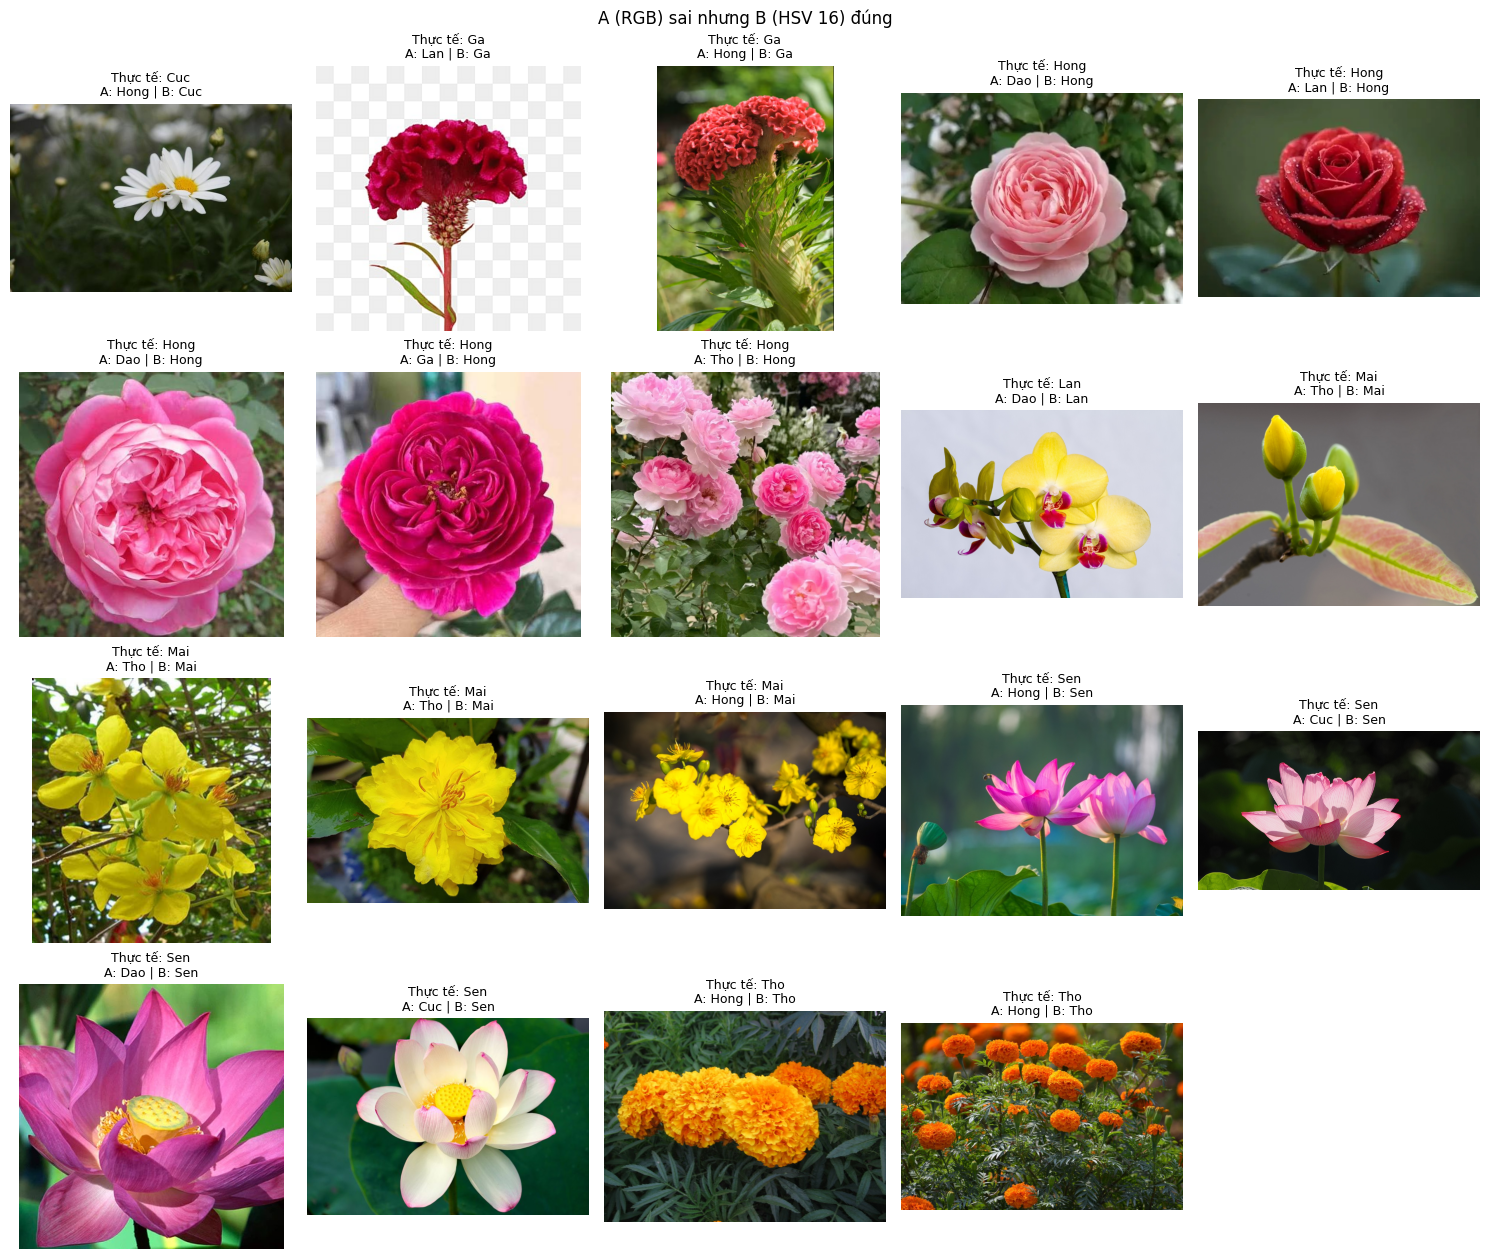

In [28]:
print_list(case1, "A SAI nhưng B ĐÚNG")
show_images(case1, "A (RGB) sai nhưng B (HSV 16) đúng")

### 3.2. A đúng nhưng B sai → minh họa ưu điểm của A

A ĐÚNG nhưng B SAI  (7 ảnh)
STT File                        Thực tế   A (RGB)   B (HSV16) 
1   Cuc/0047.jpg                Cuc       Cuc       Hong      
2   Dao/0047.jpg                Dao       Dao       Hong      
3   Ga/0044.jpg                 Ga        Ga        Hong      
4   Hong/0041.jpg               Hong      Hong      Ga        
5   Hong/0049.jpg               Hong      Hong      Ga        
6   Mai/0031.jpg                Mai       Mai       Hong      
7   Mai/0036.jpg                Mai       Mai       Ga        


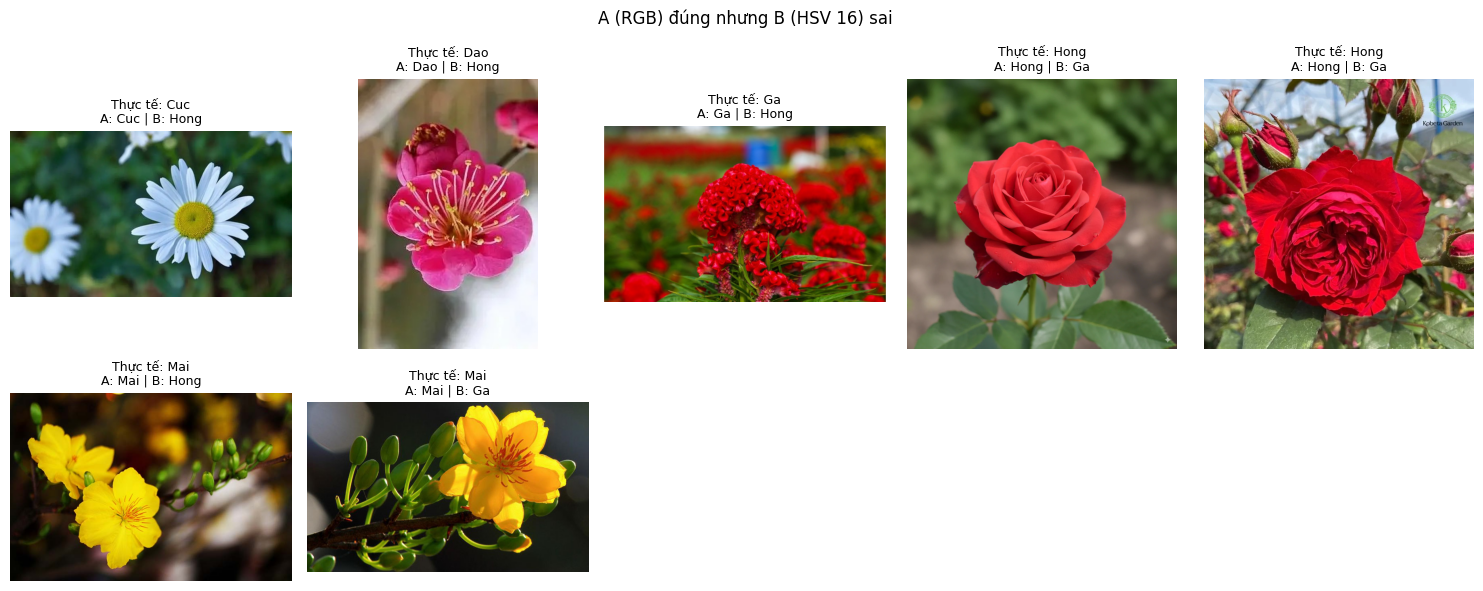

In [29]:
print_list(case2, "A ĐÚNG nhưng B SAI")
show_images(case2, "A (RGB) đúng nhưng B (HSV 16) sai")

### 3.3. A sai và B sai → những mẫu khó

A SAI và B SAI  (21 ảnh)
STT File                        Thực tế   A (RGB)   B (HSV16) 
1   Dao/0037.jpg                Dao       Lan       Ga        
2   Dao/0041.jpg                Dao       Hong      Mai       
3   Dao/0042.jpg                Dao       Ga        Ga        
4   Ga/0048.jpg                 Ga        Sen       Tho       
5   Ga/0049.jpg                 Ga        Dao       Cuc       
6   Hong/0038.jpg               Hong      Lan       Cuc       
7   Hong/0039.jpg               Hong      Ga        Ga        
8   Hong/0040.jpg               Hong      Dao       Dao       
9   Hong/0042.jpg               Hong      Ga        Ga        
10  Hong/0043.jpg               Hong      Ga        Ga        
11  Hong/0046.jpg               Hong      Cuc       Cuc       
12  Hong/0050.jpg               Hong      Sen       Ga        
13  Lan/0036.jpg                Lan       Ga        Ga        
14  Lan/0041.jpg                Lan       Cuc       Cuc       
15  Lan/0042.jpg              

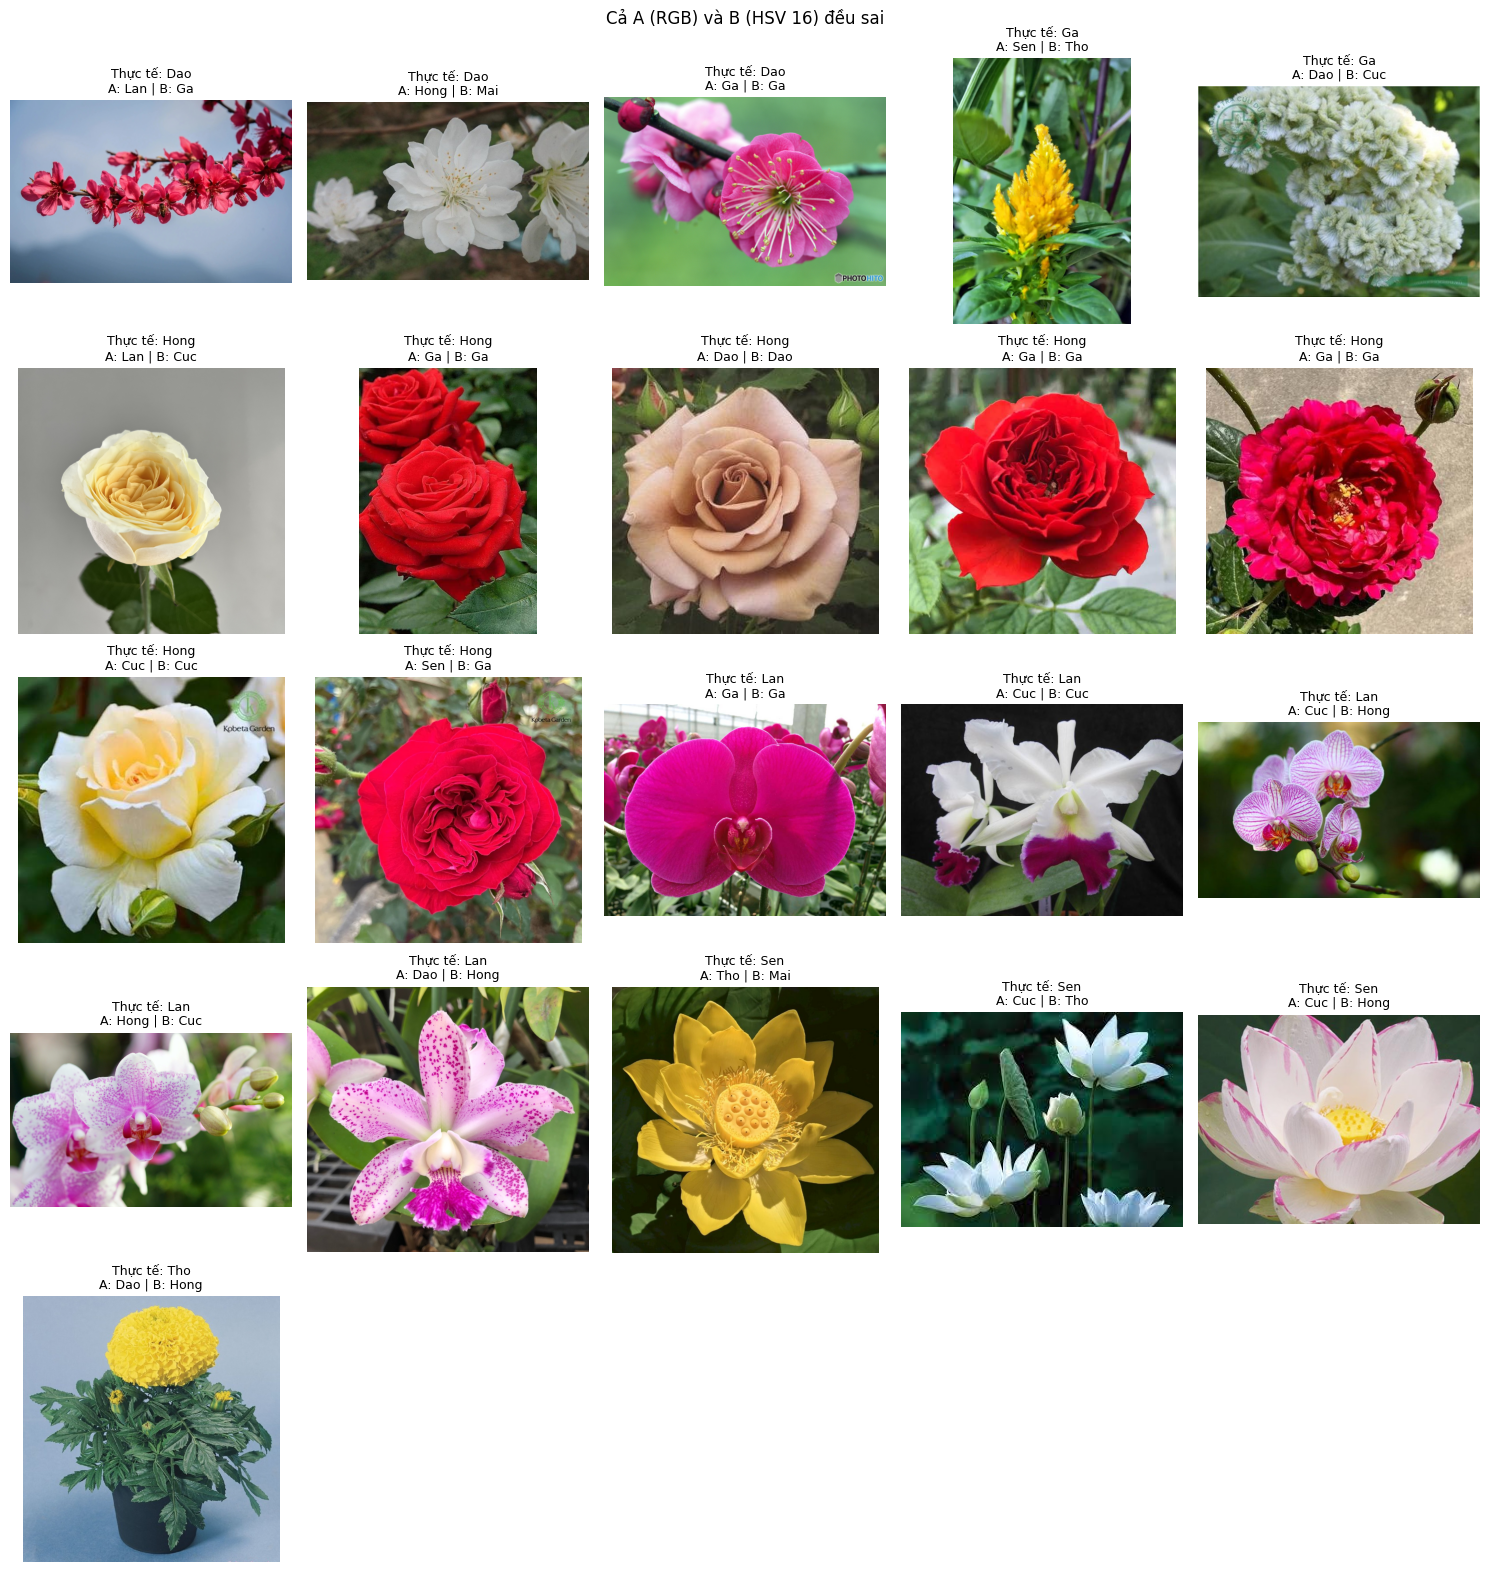

In [30]:
print_list(case3, "A SAI và B SAI")
show_images(case3, "Cả A (RGB) và B (HSV 16) đều sai")

# Nhận xét (tự viết dựa trên kết quả chạy của bạn)
* **Yêu cầu 1:** bộ tham số tối ưu là ..., accuracy = ... Metric nào cho kết quả tốt/kém và vì sao (gợi ý: histogram là phân phối xác suất nên các độ đo như braycurtis/canberra/cosine thường phù hợp hơn).
* **Yêu cầu 2:** đặc trưng nào tốt nhất/kém nhất? Giải thích (HSV tách màu sắc khỏi độ sáng; moment màu và màu chủ đạo chỉ có 9 chiều nên mất nhiều thông tin phân bố màu).
* **Yêu cầu 3:** nhận xét các ảnh ở 3 trường hợp: ảnh nào nền/ánh sáng làm RGB sai, loài hoa nào hay bị nhầm với nhau (ví dụ Đào và Mai cùng tông hồng/vàng...).